In [53]:
import pandas as pd
import torch
from plotnine import *

from vpop_calibration.api import *

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [54]:
# Setup the training data for the surrogate model
# An analytical expression is available for the model


def logistic_growth(lambda1, lambda2, lambda3, t):
    """Analytical expression of a logistic growth model

    Args:
        t: age in days
        lambda1, lambda2, lambda3: growth parameters

    Returns:
        y: Predicted concentration
    """
    y = lambda1 / (1 + torch.exp(-(t - lambda2) / lambda3))
    return y


struct_model = StructuralAnalytical(logistic_growth, ["circumference"])

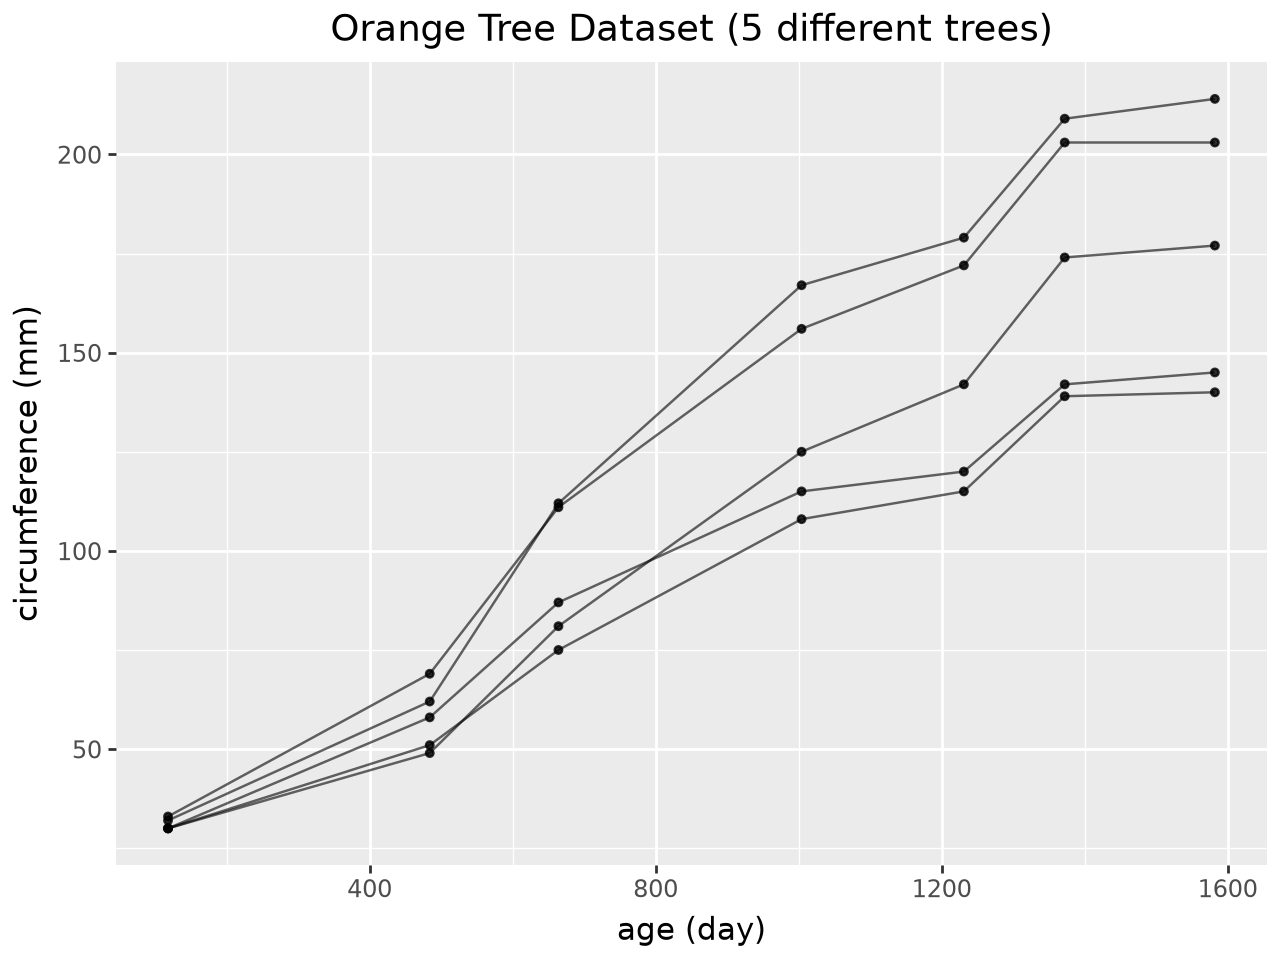

In [55]:
orange_trees_data_url = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/refs/heads/master/csv/datasets/Orange.csv"
df = pd.read_csv(orange_trees_data_url)
obs_df = (
    df.drop(columns=["rownames"])
    .rename(columns={"Tree": "id", "age": "time", "circumference": "value"})[
        ["id", "time", "value"]
    ]
    .astype({"value": "float", "time": "float"})
)
obs_df["output_name"] = "circumference"
obs_df["protocol_arm"] = "identity"
(
    ggplot(obs_df, aes(x="time", y="value", group="id"))
    + geom_line(alpha=0.6)
    + geom_point(size=1, alpha=0.8)
    + theme(legend_position="none")
    + labs(
        title="Orange Tree Dataset (5 different trees)",
        x="age (day)",
        y="circumference (mm)",
    )
)

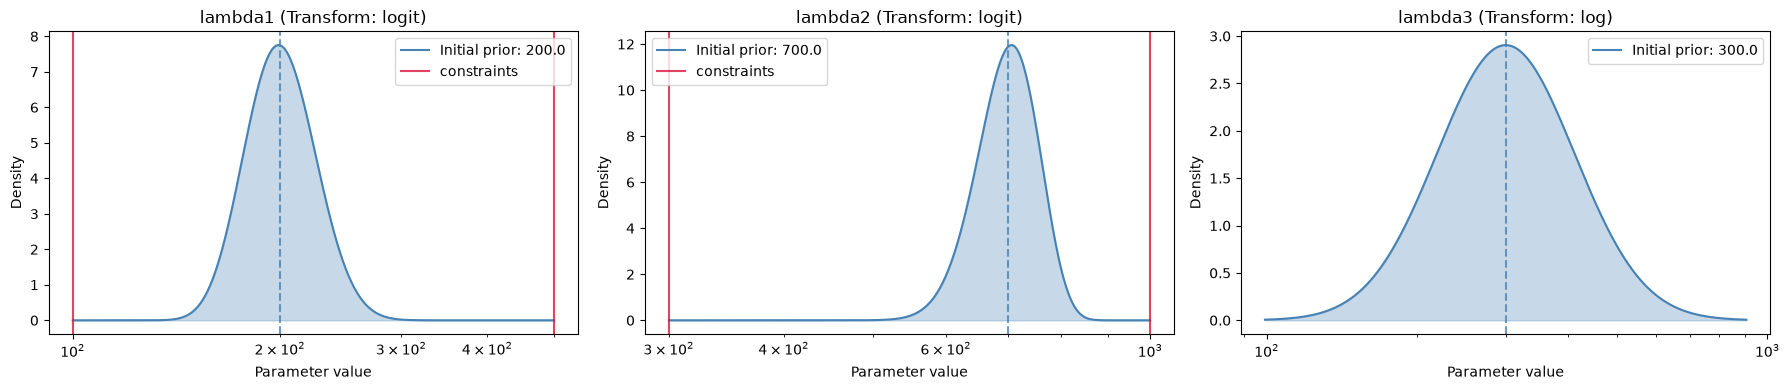

  0%|          | 0/450 [00:00<?, ?it/s]

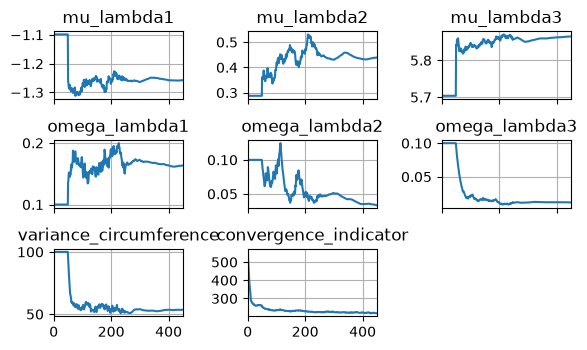

In [56]:
model_params = {
    "pdu": {
        "lambda1": {
            "prior": 200,
            "prior_omega": 0.1,
            "constraint": {"low": 100, "high": 500},
        },
        "lambda2": {
            "prior": 700,
            "prior_omega": 0.1,
            "constraint": {"low": 300, "high": 1000},
        },
        "lambda3": {"prior": 300, "prior_omega": 0.1},
    },
    "error_model": {
        "circumference": {"error_type": "additive", "initial_variance": 100.0}
    },
}
config = Config(
    nlme=NlmeConfigDict(nb_chains=10, max_samples=200),
    saem=SaemConfigDict(nb_iter_burnin=50, nb_iter_learning=200, nb_iter_smoothing=200),
)

nlme_model = NlmeModel(
    structural_model=struct_model, df=obs_df, input_params=model_params, config=config
)
nlme_model.initial_estimates.plot_distribution()
nlme_model.optimizer.run()

Simulating population:   0%|          | 0/100 [00:00<?, ?it/s]

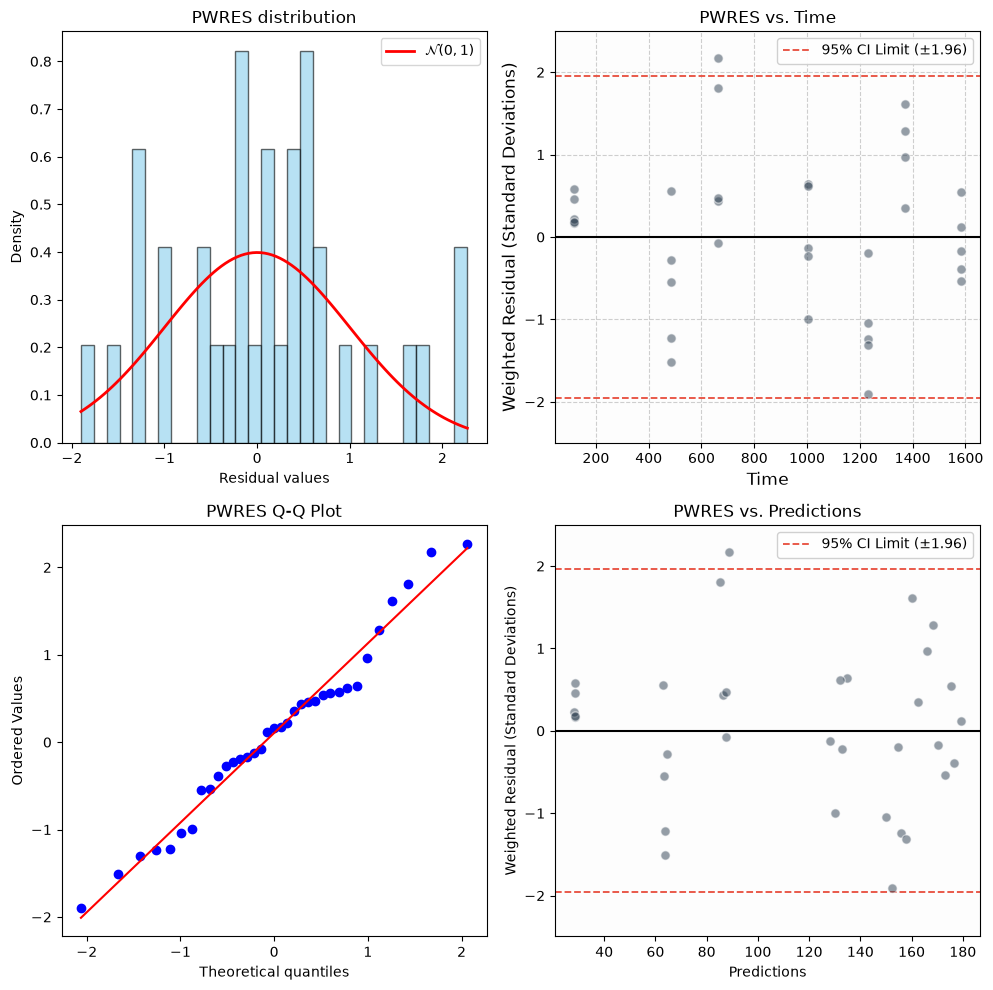

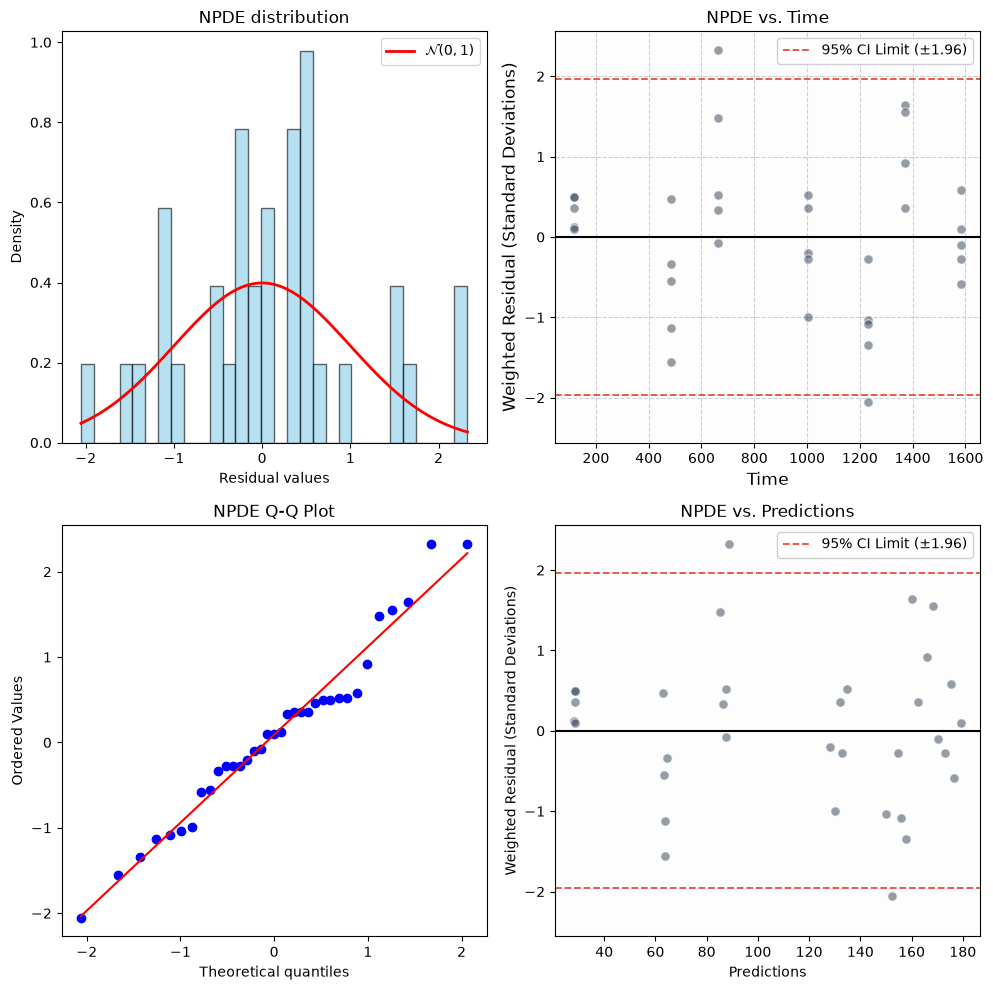

In [57]:
nlme_model.diagnostics.compute_population_diagnostics(nb_samples=100)
nlme_model.plot.weighted_residuals("pwres")
nlme_model.plot.weighted_residuals("npde")

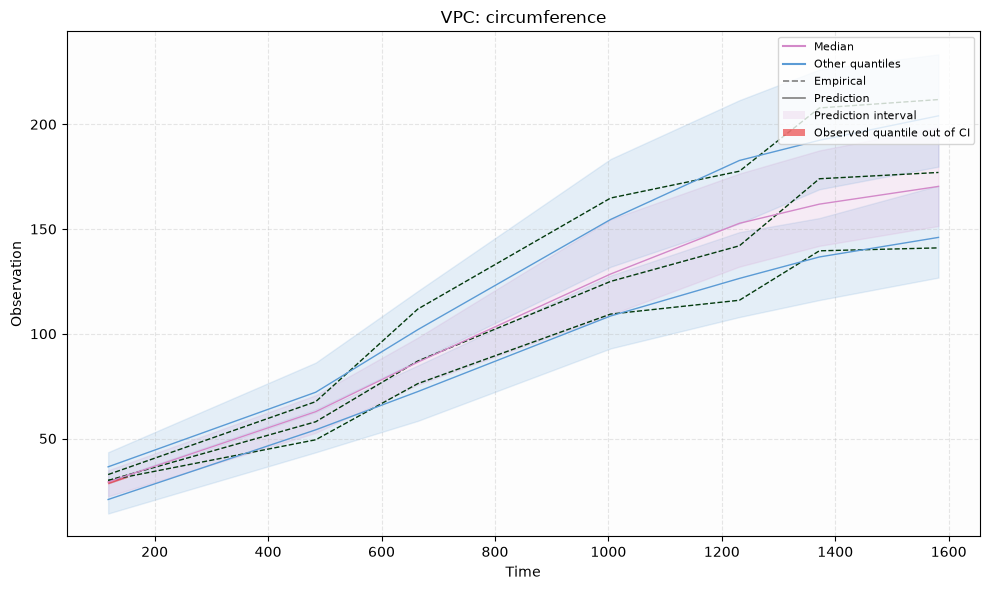

In [58]:
nlme_model.plot.vpc()

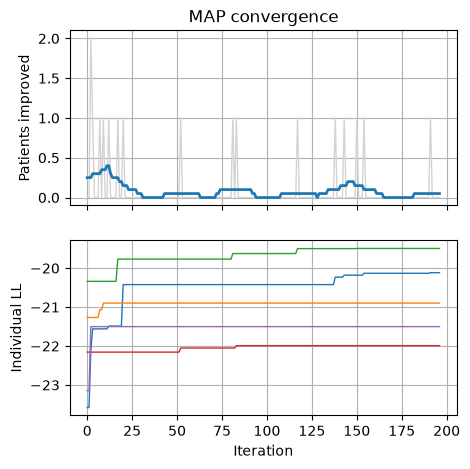

  0%|          | 0/199 [00:00<?, ?it/s]

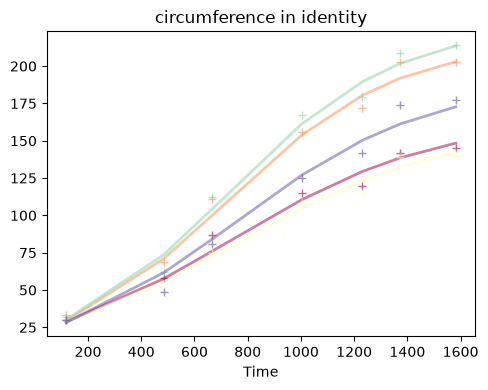

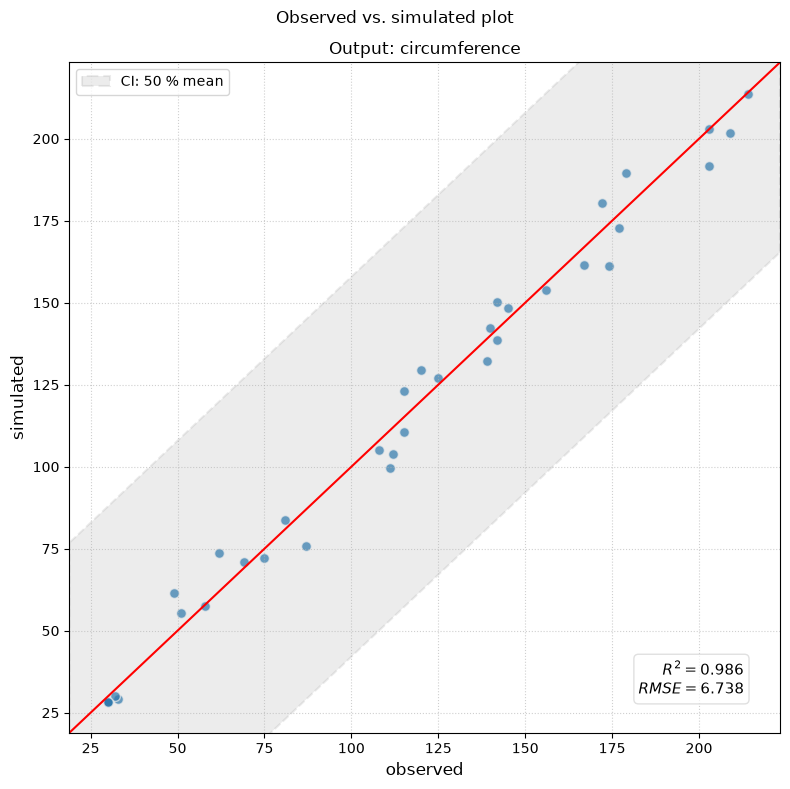

In [59]:
nlme_model.sample_conditional_distribution(200)
nlme_model.plot.map_estimates()
nlme_model.plot.map_estimates_gof()

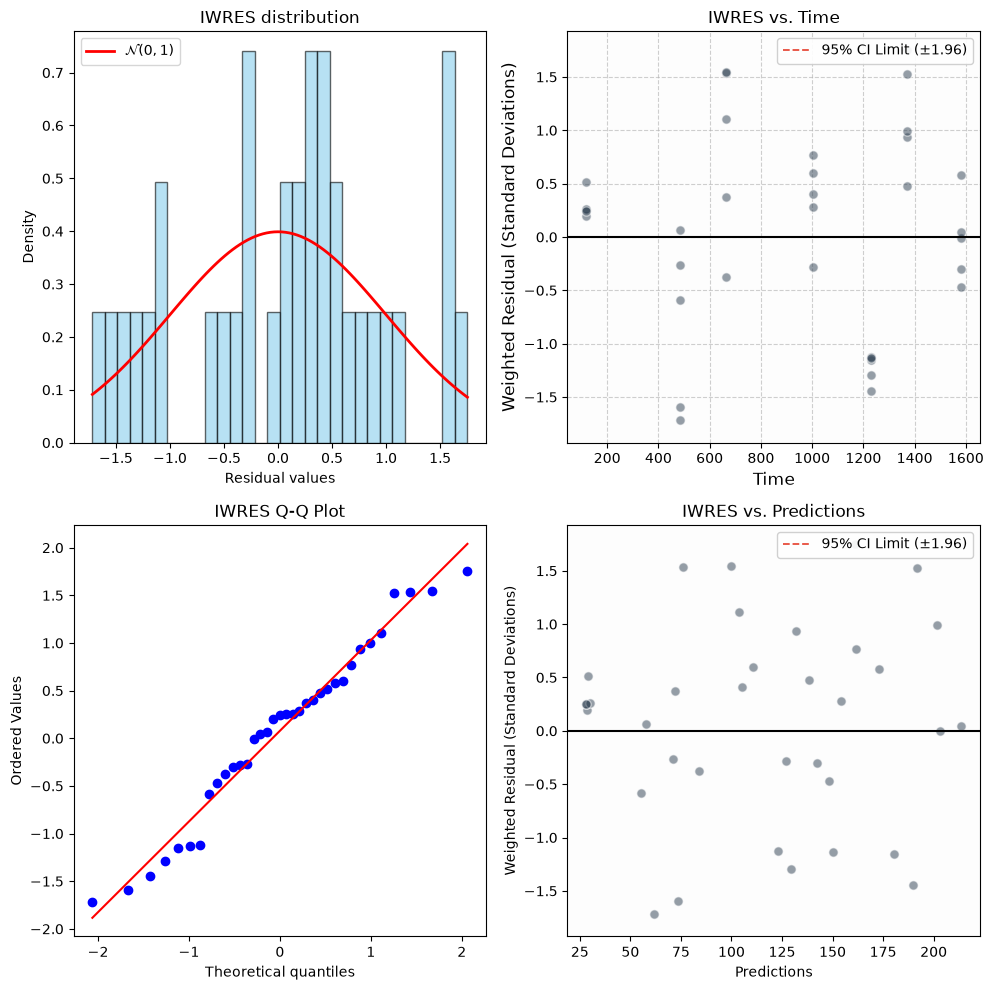

In [60]:
nlme_model.plot.weighted_residuals("iwres")

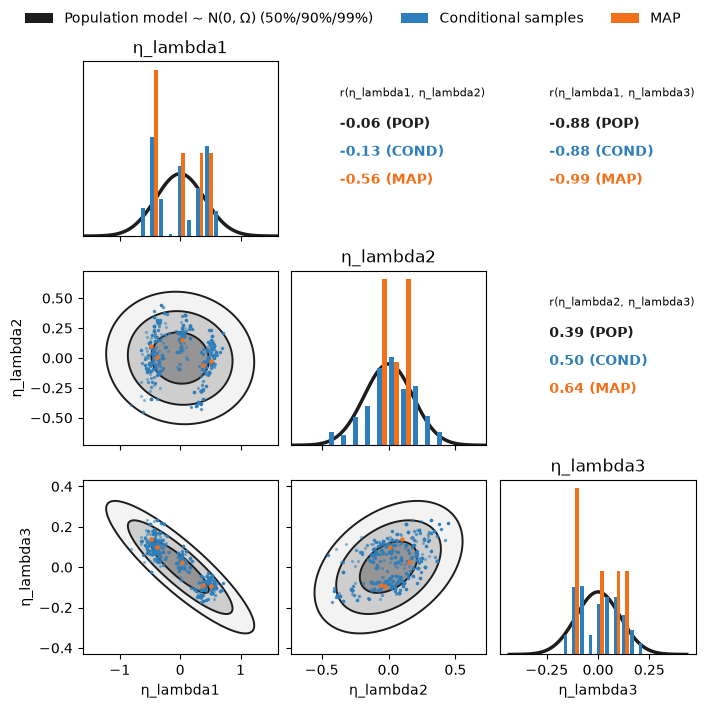

In [61]:
nlme_model.plot.conditional_codistributions(figsize=[7, 7])

In [62]:
df = nlme_model.diagnostics.report_shrinkage(nb_samples=100)
display(df.round(1))

,lambda1,lambda2,lambda3
shrinkage(%),-8.5,52.5,1.1


In [63]:
nlme_model.diagnostics.compute_log_likelihood_importance_sampling(
    nb_proposal_samples=1000
)
print(
    f"Observed-data log-likelihood estimate, -2LL = {-2*nlme_model.diagnostics.importance_sampler.log_lik:.2f}"
)

Importance sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

Observed-data log-likelihood estimate, -2LL = 260.02
